# 04 — Realisable against theoretical

Perfect foresight is the upper bound: it solves each trading day knowing every price in advance. No strategy can beat it on the same data.

The rolling-horizon strategies re-optimise every half hour on a **forecast** of the next 24 hours, commit only the next half hour, and are then **settled on actual prices**. Three deliberately naive forecasts are used — persistence, same time yesterday, and same interval last week — because a naive forecast is the honest floor. Anything a trading desk does better than that is upside the model should not assume.

Parameters were designed on 2024 and frozen in `src.strategies.FROZEN_CONFIG`. 2025 and 2026 are run with those values unchanged; `frozen_for()` is the only way the pipeline builds a configuration, and it ignores the year, so the no-tuning claim is enforced in code rather than promised.

Compute: `scripts/run_strategies.py` writes `outputs/strategy_daily.parquet`. This notebook reads it.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if str(Path.cwd().parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

from src import cases, strategies, viz
from src.paths import OUTPUTS

viz.use_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

RECOMPUTE = False  # set True for a cold run; takes roughly 20 minutes

if RECOMPUTE or not (OUTPUTS / "strategy_daily.parquet").exists():
    subprocess.run(
        [sys.executable, "scripts/run_strategies.py"], cwd=Path.cwd().parent, check=True
    )

daily = pd.read_parquet(OUTPUTS / "strategy_daily.parquet")
daily["trading_date"] = pd.to_datetime(daily["trading_date"])
daily["year"] = daily["trading_date"].dt.year
print(f"{len(daily):,} daily rows")
print(f"cases      {sorted(daily['case'].unique())}")
print(f"strategies {sorted(daily['strategy'].unique())}")
print(f"period     {daily['trading_date'].min().date()} to {daily['trading_date'].max().date()}")

26,832 daily rows
cases      ['1h_credits', '1h_merchant', '2h_credits', '2h_merchant', '4h_credits', '4h_merchant']
strategies ['last_week', 'perfect_foresight', 'persistence', 'yesterday']
period     2023-10-01 to 2026-11-01


## The frozen configuration

In [2]:
config = strategies.FROZEN_CONFIG
pd.Series(
    {
        "design year": strategies.DESIGN_YEAR,
        "horizon (intervals)": config.horizon_intervals,
        "horizon (hours)": config.horizon_intervals * 5 / 60,
        "commit (intervals)": config.commit_intervals,
        "commit (minutes)": config.commit_intervals * 5,
        "energy forecasts": ", ".join(strategies.NAIVE_FORECASTS),
        "FCESS forecast": f"trailing mean over {strategies.FCESS_FORECAST_LOOKBACK // 288} days",
        "terminal state of charge": "free within bounds",
    }
).to_frame("value")

,value
design year,2024
horizon (intervals),288
horizon (hours),24.0
commit (intervals),6
commit (minutes),30
energy forecasts,"persistence, yesterday, last_week"
FCESS forecast,trailing mean over 7 days
terminal state of charge,free within bounds


The FCESS price gets a trailing mean rather than the energy forecast rule. FCESS clears at exactly zero in a large share of intervals, so a persistence forecast taken at such an interval predicts zero across the whole horizon and the battery declines to offer at all. That is not how a price taker behaves: it offers its available capacity and is paid whatever clears, because holding a few MW of reserve out of a hundred costs almost no headroom. The trailing mean is causal and uses no information from the future.

Enablement *ceilings* are taken as actual in every strategy, including perfect foresight, because whether a battery is enabled is AEMO's dispatch decision rather than the operator's. The capture rate therefore measures what forecast error costs on the **energy** side, which is where the operator's judgement actually bites.

## The bound holds

Checked before anything else is read off these numbers. Perfect foresight closes the state of charge every day while the rolling horizon carries it across days, so a single day can exceed the bound by borrowing from its neighbour; the period total cannot.

In [3]:
checks = []
for case in sorted(daily["case"].unique()):
    subset = daily[daily["case"] == case]
    bound = subset[subset["strategy"] == "perfect_foresight"].set_index("trading_date")
    for strategy in strategies.NAIVE_FORECASTS:
        realisable = subset[subset["strategy"] == strategy].set_index("trading_date")
        check = strategies.check_bound(realisable, bound)
        check.update({"case": case, "strategy": strategy})
        checks.append(check)

bound_checks = pd.DataFrame(checks).set_index(["case", "strategy"])
assert bound_checks["bound_holds"].all(), "a strategy beat the perfect-foresight bound"
print("perfect foresight is never beaten over the period, in any case\n")
bound_checks[["days", "realisable_total", "bound_total", "days_above_bound"]].round(0)

perfect foresight is never beaten over the period, in any case



days  realisable_total  bound_total  days_above_bound
case        strategy                                                          
1h_credits  persistence  1118         9320781.0   43095272.0                 4
            yesterday    1118        14925026.0   43095272.0                35
            last_week    1118        12532622.0   43095272.0                35
1h_merchant persistence  1118         8600625.0   44990727.0                 0
            yesterday    1118        14118102.0   44990727.0                32
            last_week    1118        11572583.0   44990727.0                29
2h_credits  persistence  1118        11119139.0   58547225.0                 4
            yesterday    1118        24881990.0   58547225.0                70
            last_week    1118        21266506.0   58547225.0                58
2h_merchant persistence  1118         8564986.0   60781642.0                 0
            yesterday    1118        23859737.0   60781642.0                61
            last_week    1118        20035256.0   60781642.0                46
4h_credits  persistence  1118        14586901.0   72941998.0                 4
            yesterday    1118        38962752.0   72941998.0               152
            last_week    1118        34892240.0   72941998.0               126
4h_merchant persistence  1118         8653209.0   76404322.0                 0
            yesterday    1118        38246965.0   76404322.0               130
            last_week    1118        33230050.0   76404322.0               102

Individual days above the bound are expected and are the state-of-charge carry-over described above, not a violation.

## Annual revenue and capture rates

2023 covers October to December and 2026 runs to the most recent complete trading day, so neither is a full year. Capture rates are comparable across years; totals are not.

In [4]:
annual = (
    daily.groupby(["case", "strategy", "year"], observed=True)
    .agg(
        days=("trading_date", "nunique"),
        total=("total_revenue", "sum"),
        energy=("energy_revenue", "sum"),
        fcess=("fcess_revenue", "sum"),
        cycles=("cycles", "sum"),
    )
    .reset_index()
)
bound = annual[annual["strategy"] == "perfect_foresight"].set_index(["case", "year"])
annual["bound"] = annual.set_index(["case", "year"]).index.map(bound["total"])
annual["bound_energy"] = annual.set_index(["case", "year"]).index.map(bound["energy"])
annual["capture_rate"] = annual["total"] / annual["bound"]
annual["energy_capture_rate"] = annual["energy"] / annual["bound_energy"]
annual["$/MW-year"] = annual["total"] / cases.HEADLINE_MW / (annual["days"] / 365.25)

pivot = annual.pivot_table(
    index=["case", "year"], columns="strategy", values="total", observed=True
)
print("total revenue, $ million")
(pivot / 1e6).round(2)

total revenue, $ million


strategy          last_week  perfect_foresight  persistence  yesterday
case        year                                                      
1h_credits  2023       0.79               5.70         0.17       1.31
            2024       8.87              25.83         6.31      10.21
            2025       3.24               8.45         2.77       3.57
            2026      -0.37               3.12         0.08      -0.17
1h_merchant 2023       0.56               6.03         0.11       1.15
            2024       8.38              26.84         5.53       9.78
            2025       3.12               8.68         2.70       3.45
            2026      -0.49               3.44         0.26      -0.26
2h_credits  2023       1.85               8.08         0.43       2.84
            2024      15.02              34.85         7.69      16.68
            2025       4.75              11.28         3.05       5.37
            2026      -0.35               4.34        -0.06      -0.00
2h_merchant 2023       1.55               8.44         0.10       2.62
            2024      14.29              35.92         5.51      16.06
            2025       4.69              11.68         2.70       5.32
            2026      -0.49               4.74         0.26      -0.14
4h_credits  2023       3.76              10.05         1.03       5.04
            2024      24.29              43.49        10.12      25.71
            2025       7.00              14.12         3.51       7.83
            2026      -0.16               5.28        -0.08       0.39
4h_merchant 2023       3.28              10.52         0.11       4.83
            2024      23.08              44.95         5.58      25.06
            2025       7.17              15.00         2.70       8.10
            2026      -0.31               5.94         0.26       0.27

In [5]:
capture = annual[annual["strategy"] != "perfect_foresight"].pivot_table(
    index=["case", "year"], columns="strategy", values="capture_rate", observed=True
)
print("capture rate: realisable revenue as a share of perfect foresight")
capture.round(3)

capture rate: realisable revenue as a share of perfect foresight


strategy          last_week  persistence  yesterday
case        year                                   
1h_credits  2023      0.139        0.029      0.230
            2024      0.343        0.244      0.395
            2025      0.384        0.327      0.423
            2026     -0.119        0.024     -0.053
1h_merchant 2023      0.093        0.019      0.191
            2024      0.312        0.206      0.364
            2025      0.360        0.311      0.397
            2026     -0.143        0.074     -0.077
2h_credits  2023      0.229        0.054      0.351
            2024      0.431        0.221      0.479
            2025      0.421        0.270      0.476
            2026     -0.081       -0.013     -0.001
2h_merchant 2023      0.184        0.012      0.311
            2024      0.398        0.153      0.447
            2025      0.401        0.231      0.456
            2026     -0.104        0.054     -0.030
4h_credits  2023      0.374        0.102      0.501
            2024      0.559        0.233      0.591
            2025      0.496        0.249      0.554
            2026     -0.030       -0.014      0.073
4h_merchant 2023      0.312        0.011      0.459
            2024      0.514        0.124      0.558
            2025      0.478        0.180      0.540
            2026     -0.052        0.043      0.045

In [6]:
energy_capture = annual[annual["strategy"] != "perfect_foresight"].pivot_table(
    index=["case", "year"], columns="strategy", values="energy_capture_rate", observed=True
)
print("capture rate on the energy component alone, where the forecast actually matters")
energy_capture.round(3)

capture rate on the energy component alone, where the forecast actually matters


strategy          last_week  persistence  yesterday
case        year                                   
1h_credits  2023      0.171        0.054      0.259
            2024      0.243        0.094      0.304
            2025      0.202        0.029      0.256
            2026     -0.082       -0.032     -0.020
1h_merchant 2023      0.127        0.038      0.222
            2024      0.213        0.052      0.272
            2025      0.177        0.002      0.228
            2026     -0.104        0.000     -0.041
2h_credits  2023      0.253        0.072      0.371
            2024      0.379        0.112      0.431
            2025      0.334        0.057      0.403
            2026     -0.017       -0.040      0.057
2h_merchant 2023      0.209        0.026      0.332
            2024      0.344        0.036      0.398
            2025      0.313        0.001      0.382
            2026     -0.043        0.000      0.026
4h_credits  2023      0.392        0.117      0.515
            2024      0.540        0.148      0.574
            2025      0.472        0.088      0.540
            2026      0.056       -0.020      0.152
4h_merchant 2023      0.331        0.022      0.473
            2024      0.491        0.030      0.537
            2025      0.451        0.001      0.523
            2026      0.026        0.000      0.116

## Design year against test years

The test of whether the strategy generalises. Parameters were chosen on 2024 and applied unchanged; if the capture rate collapses in 2025 or 2026, the design was fitted to one year's price shape.

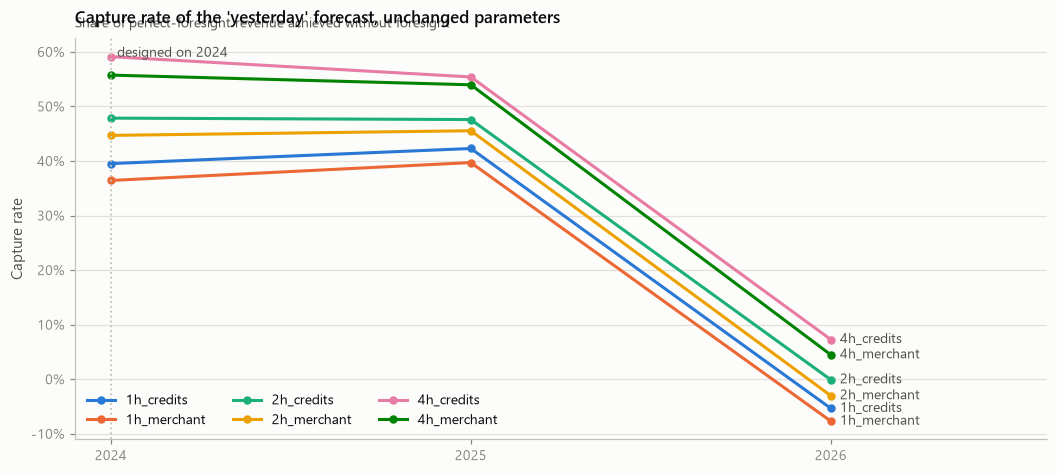

In [7]:
best = "yesterday"
fig, ax = viz.figure(9.5, 4.2)

subset = annual[(annual["strategy"] == best) & (annual["year"] >= 2024)]
for slot, case in enumerate(sorted(subset["case"].unique())):
    rows = subset[subset["case"] == case].sort_values("year")
    ax.plot(rows["year"], rows["capture_rate"], marker="o", color=viz.SERIES[slot], label=case)
    viz.label_last(ax, rows["year"].iloc[-1], rows["capture_rate"].iloc[-1], case, viz.SERIES[slot])

ax.axvline(strategies.DESIGN_YEAR, color=viz.AXIS, linestyle=":", linewidth=1.2)
ax.annotate(
    "designed on 2024",
    xy=(strategies.DESIGN_YEAR, ax.get_ylim()[1]),
    xytext=(4, -12),
    textcoords="offset points",
    fontsize=9,
    color=viz.INK_SECONDARY,
)
ax.set_xticks(sorted(subset["year"].unique()))
viz.percent(ax)
viz.finish(
    ax,
    f"Capture rate of the '{best}' forecast, unchanged parameters",
    subtitle="Share of perfect-foresight revenue achieved without foresight",
    ylabel="Capture rate",
)
ax.set_xlim(right=subset["year"].max() + 0.6)
ax.legend(loc="lower left", ncols=3)
plt.show()

## Revenue by duration and strategy, full period

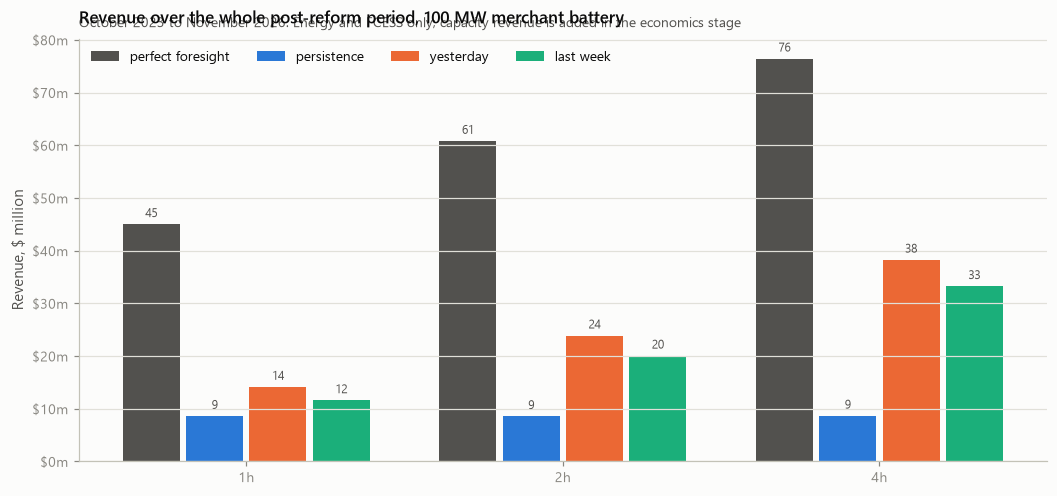

In [8]:
merchant = daily[daily["case"].str.endswith("merchant")]
period = (
    merchant.groupby(["case", "strategy"], observed=True)["total_revenue"].sum().unstack()
)
order = ["perfect_foresight", *strategies.NAIVE_FORECASTS]
period = period[order]

fig, ax = viz.figure(9.5, 4.4)
x = np.arange(len(period))
width = 0.2

for slot, strategy in enumerate(order):
    colour = viz.INK_SECONDARY if strategy == "perfect_foresight" else viz.SERIES[slot - 1]
    bars = ax.bar(
        x + (slot - 1.5) * width,
        period[strategy] / 1e6,
        width=width * 0.9,
        color=colour,
        label=strategy.replace("_", " "),
    )
    ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=8, color=viz.INK_SECONDARY)

ax.set_xticks(x)
ax.set_xticklabels([c.replace("_merchant", "") for c in period.index])
viz.money(ax, unit="m")
viz.finish(
    ax,
    "Revenue over the whole post-reform period, 100 MW merchant battery",
    subtitle="October 2023 to November 2026. Energy and FCESS only; capacity revenue is added in the economics stage",
    ylabel="Revenue, $ million",
)
ax.legend(loc="upper left", ncols=4)
plt.show()

## How the opportunity moved through the period

Monthly revenue for the 2-hour merchant case. The collapse matters more than the capture rate: it is the direct consequence of batteries connecting.

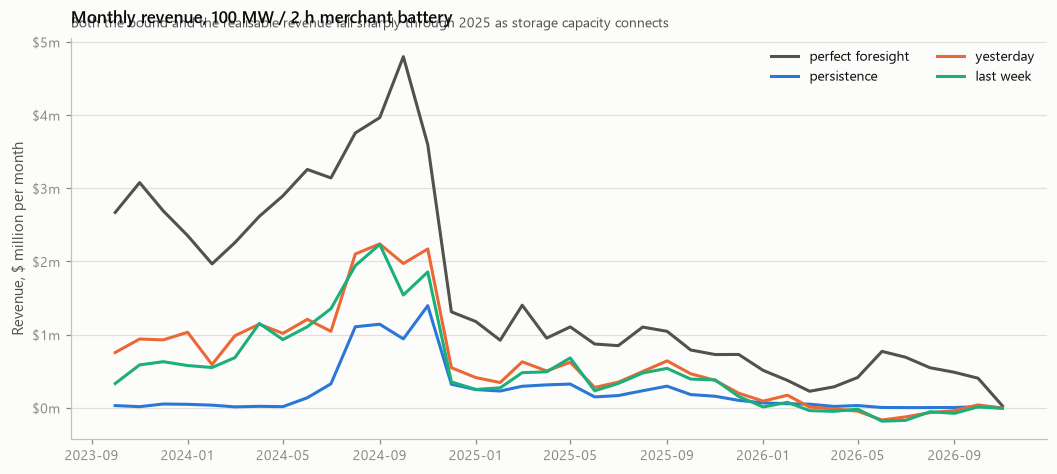

In [9]:
two_hour = daily[daily["case"] == "2h_merchant"].copy()
two_hour["month"] = two_hour["trading_date"].dt.to_period("M").dt.to_timestamp()
monthly = two_hour.pivot_table(
    index="month", columns="strategy", values="total_revenue", aggfunc="sum", observed=True
)

fig, ax = viz.figure(9.5, 4.2)
for slot, strategy in enumerate(order):
    colour = viz.INK_SECONDARY if strategy == "perfect_foresight" else viz.SERIES[slot - 1]
    ax.plot(monthly.index, monthly[strategy] / 1e6, color=colour, label=strategy.replace("_", " "))

viz.money(ax, unit="m")
viz.finish(
    ax,
    "Monthly revenue, 100 MW / 2 h merchant battery",
    subtitle="Both the bound and the realisable revenue fall sharply through 2025 as storage capacity connects",
    ylabel="Revenue, $ million per month",
)
ax.legend(loc="upper right", ncols=2)
plt.show()

## What the obligation costs

Holding Capacity Credits forbids charging inside the obligation window and requires enough energy to be held when it opens. The cost shown here is energy and FCESS revenue forgone; the Reserve Capacity revenue that pays for it is added in the economics stage.

In [10]:
obligation = (
    daily.groupby(["case", "strategy"], observed=True)["total_revenue"].sum().unstack(level=0)
)
rows = []
for duration in ("1h", "2h", "4h"):
    for strategy in order:
        free = obligation.loc[strategy, f"{duration}_merchant"]
        obliged = obligation.loc[strategy, f"{duration}_credits"]
        rows.append(
            {
                "duration": duration,
                "strategy": strategy,
                "merchant $m": free / 1e6,
                "with credits $m": obliged / 1e6,
                "obligation cost $m": (free - obliged) / 1e6,
                "obligation cost %": (free - obliged) / free,
            }
        )
pd.DataFrame(rows).set_index(["duration", "strategy"]).round(3)

merchant $m  with credits $m  obligation cost $m  obligation cost %
duration strategy                                                                              
1h       perfect_foresight       44.991           43.095               1.895              0.042
         persistence              8.601            9.321              -0.720             -0.084
         yesterday               14.118           14.925              -0.807             -0.057
         last_week               11.573           12.533              -0.960             -0.083
2h       perfect_foresight       60.782           58.547               2.234              0.037
         persistence              8.565           11.119              -2.554             -0.298
         yesterday               23.860           24.882              -1.022             -0.043
         last_week               20.035           21.267              -1.231             -0.061
4h       perfect_foresight       76.404           72.942               3.462              0.045
         persistence              8.653           14.587              -5.934             -0.686
         yesterday               38.247           38.963              -0.716             -0.019
         last_week               33.230           34.892              -1.662             -0.050

In [11]:
breaches = daily.groupby(["case", "strategy"], observed=True)["obligation_breaches"].max()
print("solves in which the battery could not meet the obligation window and dispatched anyway:")
breaches[breaches > 0].to_frame("breaches") if (breaches > 0).any() else print("  none")

solves in which the battery could not meet the obligation window and dispatched anyway:
  none


## Summary for the write-up

In [12]:
headline = annual[(annual["year"].isin([2024, 2025])) & (annual["case"].str.endswith("merchant"))]
summary = headline.pivot_table(
    index=["year", "case"],
    columns="strategy",
    values=["$/MW-year", "capture_rate"],
    observed=True,
)
summary.round(3).to_csv(OUTPUTS / "capture_rate_summary.csv")
summary.round(3)

$/MW-year                                           capture_rate                                        
strategy           last_week perfect_foresight persistence   yesterday    last_week perfect_foresight persistence yesterday
year case                                                                                                                  
2024 1h_merchant   84580.845        270831.495   55797.766   98679.537        0.312               1.0       0.206     0.364
     2h_merchant  144199.107        362415.833   55599.150  162005.965        0.398               1.0       0.153     0.447
     4h_merchant  232887.206        453511.509   56334.774  252833.518        0.514               1.0       0.124     0.558
2025 1h_merchant   31415.406         87354.997   27190.931   34696.245        0.360               1.0       0.311     0.397
     2h_merchant   47176.666        117551.012   27168.693   53546.583        0.401               1.0       0.231     0.456
     4h_merchant   72164.649        150935.908   27190.027   81466.447        0.478               1.0       0.180     0.540